# First-Job Financial Decision Intelligence
### CART Classification + CART Regression

**Student:** KUNAPULI BALA SRI SARVANI  
**Student ID:** 2300030957

**Implementation focus:** dataset → encoding → train/test split → manual split calculations → CART training → pruning → evaluation → tree visualisation → prediction.

- **Classification:** predict the financial goal to prioritise using Gini impurity.
- **Regression:** predict the monthly savings-allocation percentage using squared-error (MSE).

All records are synthetic. The targets represent a simulated planning-panel process, not real financial advice.

## 1. CART implementation workflow

The notebook implements both CART tasks using the same financial-profile inputs. The classification and regression targets are different, so each task has its own tree.

**Main implementation steps**
1. Create and inspect the dataset.
2. Separate input features and target variables.
3. Encode categorical inputs and split training/testing data.
4. Calculate candidate split quality manually.
5. Fit CART trees and control overfitting with pruning.
6. Evaluate on held-out test data.
7. Visualise the fitted trees, inspect rules and predict a new profile.


## Setup — Import libraries and set a random seed


In [1]:

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, KFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree, export_text
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, ConfusionMatrixDisplay,
    mean_absolute_error, mean_squared_error, r2_score
)

RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 40)

print("Libraries imported successfully.")


Libraries imported successfully.


## 2. Create the dataset

Each row is one synthetic first-job financial profile. The input columns represent income, expenses, savings, family responsibilities, stability and personal priorities.

In [2]:

N = 2000

salary = np.clip(rng.lognormal(np.log(42000), 0.38, N), 18000, 110000)
expense_ratio = np.clip(rng.normal(0.48, 0.12, N), 0.22, 0.82)
monthly_expenses = salary * expense_ratio
existing_savings = np.clip(rng.lognormal(np.log(42000), 1.0, N), 0, 500000)

emergency_fund_status = np.where(
    existing_savings >= monthly_expenses * rng.uniform(2.0, 3.0, N), "Yes", "No"
)
family_dependants = rng.choice([0, 1, 2, 3, 4, 5], N,
                               p=[0.12, 0.20, 0.25, 0.22, 0.14, 0.07])
debt_ratio = np.clip(rng.beta(1.5, 5.5, N), 0, 0.75)
outstanding_debt = np.where(rng.random(N) < 0.42,
                            salary * rng.uniform(1, 18, N) * debt_ratio,
                            0)
job_stability = rng.choice(["Low", "Medium", "High"], N, p=[0.22, 0.48, 0.30])
parents_medical = rng.choice(["Yes", "No"], N, p=[0.28, 0.72])
car_requirement = rng.choice(["Low", "Medium", "High"], N, p=[0.35, 0.43, 0.22])
housing_priority = rng.choice(["Low", "Medium", "High"], N, p=[0.30, 0.45, 0.25])
risk_tolerance = rng.choice(["Low", "Medium", "High"], N, p=[0.38, 0.44, 0.18])
goal_urgency = rng.choice(["Low", "Medium", "High"], N, p=[0.20, 0.48, 0.32])
family_gifting_importance = rng.choice(["Low", "Medium", "High"], N, p=[0.28, 0.45, 0.27])
travel_importance = rng.choice(["Low", "Medium", "High"], N, p=[0.30, 0.44, 0.26])
shopping_importance = rng.choice(["Low", "Medium", "High"], N, p=[0.30, 0.46, 0.24])
transport_access = rng.choice(["Good", "Limited"], N, p=[0.62, 0.38])
financial_support_network = rng.choice(["Available", "Limited"], N, p=[0.56, 0.44])

financial_data = pd.DataFrame({
    "Monthly_Salary": salary.round(0),
    "Monthly_Expenses": monthly_expenses.round(0),
    "Existing_Savings": existing_savings.round(0),
    "Emergency_Fund_Status": emergency_fund_status,
    "Family_Dependants": family_dependants,
    "Outstanding_Debt": outstanding_debt.round(0),
    "Job_Stability": job_stability,
    "Parents_Medical_Responsibility": parents_medical,
    "Car_Requirement": car_requirement,
    "Housing_Priority": housing_priority,
    "Risk_Tolerance": risk_tolerance,
    "Goal_Urgency": goal_urgency,
    "Family_Gifting_Importance": family_gifting_importance,
    "Travel_Importance": travel_importance,
    "Shopping_Importance": shopping_importance,
    "Transport_Access": transport_access,
    "Financial_Support_Network": financial_support_network
})

display(financial_data.head(10))
print("Dataset shape:", financial_data.shape)


,Monthly_Salary,Monthly_Expenses,Existing_Savings,Emergency_Fund_Status,Family_Dependants,Outstanding_Debt,Job_Stability,Parents_Medical_Responsibility,Car_Requirement,Housing_Priority,Risk_Tolerance,Goal_Urgency,Family_Gifting_Importance,Travel_Importance,Shopping_Importance,Transport_Access,Financial_Support_Network
0,47156.0,20077.0,54102.0,Yes,3,0.0,High,Yes,High,Low,Low,Low,Medium,Low,Medium,Limited,Limited
1,28289.0,11318.0,102811.0,Yes,1,18507.0,Medium,No,High,High,Low,Medium,Medium,Low,High,Good,Available
2,55860.0,29722.0,55202.0,No,1,240441.0,High,Yes,High,Medium,Medium,Medium,Low,Medium,Medium,Good,Available
3,60044.0,30636.0,394059.0,Yes,4,43064.0,Medium,Yes,High,Medium,Low,High,High,Medium,Low,Good,Available
4,20011.0,6232.0,175468.0,Yes,0,0.0,Low,No,Medium,Medium,High,Medium,Medium,Medium,Low,Good,Available
5,25606.0,15741.0,30881.0,No,2,105516.0,High,No,Medium,Medium,Low,High,High,Low,Low,Good,Limited
6,44091.0,20665.0,30558.0,No,2,0.0,Low,No,Medium,Medium,Low,Medium,High,Medium,Medium,Good,Available
7,37244.0,12912.0,67179.0,Yes,3,0.0,High,Yes,Medium,Low,Low,High,High,Low,Medium,Good,Available
8,41733.0,25985.0,18168.0,No,4,0.0,High,Yes,Medium,High,Low,Low,Low,Low,Medium,Good,Limited
9,30372.0,16859.0,134822.0,Yes,3,0.0,Medium,No,Medium,Medium,Low,High,Medium,Medium,High,Limited,Limited


Dataset shape: (2000, 17)


## 3. Create the two target variables

- **Classification target:** `Recommended_Goal` (one of seven categories).
- **Regression target:** `Recommended_Savings_Percentage` (continuous numeric value).

The simulated panel combines several interacting factors and modest case-level variation. This avoids defining the answer using one simple salary threshold.

In [3]:

goal_names = [
    "Emergency Fund", "Parents' Gold", "First Car",
    "House Savings", "Family Gifts", "Travel", "Shopping"
]

# Convert understandable categories to numeric levels only inside the
# synthetic panel's scoring process.
level = {
    "Low": 0.0, "Medium": 1.0, "High": 2.0,
    "No": 0.0, "Yes": 1.0,
    "Good": 0.0, "Limited": 1.0,
    "Available": 0.0
}

def val(column):
    return financial_data[column].map(level).to_numpy(dtype=float)

salary_arr = financial_data["Monthly_Salary"].to_numpy()
expense_ratio_arr = (financial_data["Monthly_Expenses"] / financial_data["Monthly_Salary"]).to_numpy()
savings_ratio_arr = (financial_data["Existing_Savings"] / (financial_data["Monthly_Expenses"] + 1)).to_numpy()
debt_burden_arr = (financial_data["Outstanding_Debt"] / (12 * financial_data["Monthly_Salary"] + 1)).to_numpy()

emergency_no = 1 - val("Emergency_Fund_Status")
job_low = (financial_data["Job_Stability"].to_numpy() == "Low").astype(float)
job_high = (financial_data["Job_Stability"].to_numpy() == "High").astype(float)
parents_med = val("Parents_Medical_Responsibility")
car_need = val("Car_Requirement")
house_need = val("Housing_Priority")
risk_low = (financial_data["Risk_Tolerance"].to_numpy() == "Low").astype(float)
urgency = val("Goal_Urgency")
family_need = val("Family_Gifting_Importance")
travel_need = val("Travel_Importance")
shopping_need = val("Shopping_Importance")
transport_limited = val("Transport_Access")
dependants = financial_data["Family_Dependants"].to_numpy(dtype=float)
support_limited = (financial_data["Financial_Support_Network"].to_numpy() == "Limited").astype(float)

# Multiple interacting considerations create a score for each goal.
# The noise terms represent differences in individual circumstances and
# reasonable planner judgement not captured by the available columns.
base_scores = np.column_stack([
    1.55*emergency_no + 0.85*np.maximum(expense_ratio_arr-0.40, 0)*3
      + 0.65*job_low + 0.40*debt_burden_arr*3 + 0.18*dependants
      + 0.25*risk_low + 0.22*support_limited,
    0.62*parents_med + 0.30*dependants + 0.30*family_need
      + 0.20*np.minimum(savings_ratio_arr, 4) + 0.12*urgency,
    0.85*car_need + 0.62*transport_limited + 0.25*urgency
      + 0.18*job_high - 0.55*debt_burden_arr,
    0.95*house_need + 0.40*job_high + 0.20*np.minimum(savings_ratio_arr, 4)
      + 0.20*urgency - 0.55*debt_burden_arr - 0.22*job_low,
    0.90*family_need + 0.38*parents_med + 0.18*dependants + 0.22*urgency,
    0.92*travel_need + 0.35*urgency + 0.18*job_high,
    0.90*shopping_need + 0.30*urgency + 0.15*(financial_data["Risk_Tolerance"].to_numpy() == "High")
])

# Panel variation: each case receives modest judgement variation. The
# variation is intentionally not included as a model feature.
panel_noise = rng.normal(0, 0.42, size=base_scores.shape)
individual_preference_noise = rng.normal(0, 0.18, size=base_scores.shape)
panel_scores = base_scores + panel_noise + individual_preference_noise

# A small case-specific tie-breaker avoids a fixed ordering deciding ties.
panel_scores += rng.uniform(-0.03, 0.03, size=panel_scores.shape)

chosen_goal_idx = panel_scores.argmax(axis=1)
financial_data["Recommended_Goal"] = np.array(goal_names)[chosen_goal_idx]

# Regression target: recommended monthly allocation as % of take-home salary.
# Allocation depends on available monthly surplus, the selected goal's urgency,
# financial pressure, and panel variation. It is capped to avoid unrealistic
# recommendations. The target is continuous and contains case-level variation.
monthly_surplus_ratio = np.clip(
    (financial_data["Monthly_Salary"] - financial_data["Monthly_Expenses"]
     - np.minimum(financial_data["Outstanding_Debt"], financial_data["Monthly_Salary"]*0.35))
    / financial_data["Monthly_Salary"],
    0.02, 0.70
)

goal_intensity = panel_scores.max(axis=1)
allocation_noise = rng.normal(0, 2.2, N)
allocation_preference = rng.normal(0, 1.4, N)

recommended_pct = (
    4.5
    + 0.13 * np.clip(goal_intensity, 0, 7)
    + 16.0 * monthly_surplus_ratio
    + 1.8 * urgency
    - 1.4 * risk_low
    + allocation_noise
    + allocation_preference
)
# Limit allocations by affordability, while preserving non-zero variability.
recommended_pct = np.minimum(recommended_pct, 100 * monthly_surplus_ratio * 0.65)
recommended_pct = np.clip(recommended_pct, 2.0, 35.0)

financial_data["Recommended_Savings_Percentage"] = recommended_pct.round(2)

display(financial_data[["Recommended_Goal", "Recommended_Savings_Percentage"]].head(12))
print("\nRecommended-goal counts:")
display(financial_data["Recommended_Goal"].value_counts().rename_axis("Goal").to_frame("Cases"))
print("\nSavings percentage summary:")
display(financial_data["Recommended_Savings_Percentage"].describe().to_frame())


,Recommended_Goal,Recommended_Savings_Percentage
0,First Car,9.49
1,House Savings,12.37
2,Emergency Fund,6.89
3,Family Gifts,9.09
4,House Savings,19.89
5,Emergency Fund,2.29
6,Emergency Fund,8.76
7,Family Gifts,16.33
8,Emergency Fund,11.26
9,Shopping,15.25



Recommended-goal counts:


,Cases
Goal,
Emergency Fund,654
House Savings,359
Parents' Gold,292
Family Gifts,265
First Car,154
Travel,151
Shopping,125



Savings percentage summary:


,Recommended_Savings_Percentage
count,2000.000000
mean,11.908620
std,4.820105
min,2.000000
25%,8.767500
50%,12.275000
75%,15.460000
max,23.940000


## 4. Inspect the dataset

Check the shape, missing values, duplicates and target distributions before fitting the trees.

Missing values: 0
Duplicate rows: 0


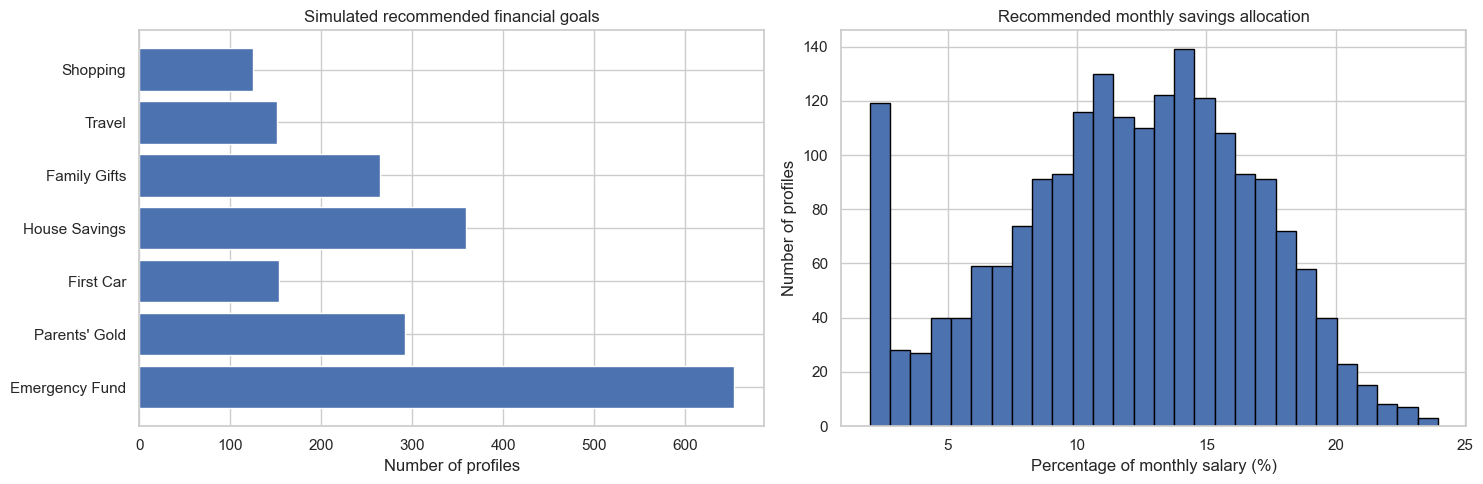

In [4]:

print("Missing values:", int(financial_data.isna().sum().sum()))
print("Duplicate rows:", int(financial_data.duplicated().sum()))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
goal_counts = financial_data["Recommended_Goal"].value_counts().reindex(goal_names)
axes[0].barh(goal_counts.index, goal_counts.values)
axes[0].set_title("Simulated recommended financial goals")
axes[0].set_xlabel("Number of profiles")

axes[1].hist(financial_data["Recommended_Savings_Percentage"], bins=28, edgecolor="black")
axes[1].set_title("Recommended monthly savings allocation")
axes[1].set_xlabel("Percentage of monthly salary (%)")
axes[1].set_ylabel("Number of profiles")

plt.tight_layout()
plt.show()


## 5. Prepare features and split the data

Separate inputs from both targets and create training and testing sets. Categorical inputs are represented using every unique binary partition, matching the manual CART split calculations.

In [5]:
target_class = "Recommended_Goal"
target_reg = "Recommended_Savings_Percentage"

feature_columns = [
    "Monthly_Salary", "Monthly_Expenses", "Existing_Savings",
    "Emergency_Fund_Status", "Family_Dependants", "Outstanding_Debt",
    "Job_Stability", "Parents_Medical_Responsibility", "Car_Requirement",
    "Housing_Priority", "Risk_Tolerance", "Goal_Urgency",
    "Family_Gifting_Importance", "Travel_Importance", "Shopping_Importance",
    "Transport_Access", "Financial_Support_Network"
]

X = financial_data[feature_columns].copy()
y_class = financial_data[target_class].copy()
y_reg = financial_data[target_reg].copy()

X_train, X_test, y_class_train, y_class_test = train_test_split(
    X, y_class, test_size=0.25, random_state=RANDOM_STATE, stratify=y_class
)
y_reg_train = y_reg.loc[X_train.index]
y_reg_test = y_reg.loc[X_test.index]

categorical_columns = X.select_dtypes(include=["object"]).columns.tolist()
numeric_columns = X.select_dtypes(exclude=["object"]).columns.tolist()

class CategoricalPartitionEncoder(BaseEstimator, TransformerMixin):
    """Create one binary column for every unique A-versus-not-A partition."""
    def fit(self, X, y=None):
        frame = pd.DataFrame(X).copy()
        self.columns_ = list(frame.columns)
        self.categories_ = {}
        self.partitions_ = {}
        self.feature_names_out_ = []
        for column in self.columns_:
            categories = sorted(pd.Series(frame[column]).dropna().unique().tolist(), key=str)
            self.categories_[column] = categories
            partitions = unique_binary_partitions(categories)
            self.partitions_[column] = partitions
            for left, right in partitions:
                left_name = "+".join(map(str, sorted(left, key=str)))
                right_name = "+".join(map(str, sorted(right, key=str)))
                self.feature_names_out_.append(f"{column}[{left_name} | {right_name}]")
        return self

    def transform(self, X):
        frame = pd.DataFrame(X, columns=self.columns_).copy()
        encoded = []
        for column in self.columns_:
            for left, right in self.partitions_[column]:
                encoded.append(frame[column].isin(left).astype(float).to_numpy())
        if not encoded:
            return np.empty((len(frame), 0))
        return np.column_stack(encoded)

    def get_feature_names_out(self, input_features=None):
        return np.asarray(self.feature_names_out_, dtype=object)

# The same binary partitions used in the manual CART calculations are now
# supplied to the actual sklearn trees. Numeric columns remain unchanged.
preprocessor = ColumnTransformer([
    ("categorical_partitions", CategoricalPartitionEncoder(), categorical_columns),
    ("numeric", "passthrough", numeric_columns)
], verbose_feature_names_out=False)

print("Training profiles:", len(X_train))
print("Testing profiles:", len(X_test))
print("Categorical columns:", categorical_columns)
print("Numeric columns:", numeric_columns)
print("Categorical features are represented by all unique binary partitions.")


Training profiles: 1500
Testing profiles: 500
Categorical columns: ['Emergency_Fund_Status', 'Job_Stability', 'Parents_Medical_Responsibility', 'Car_Requirement', 'Housing_Priority', 'Risk_Tolerance', 'Goal_Urgency', 'Family_Gifting_Importance', 'Travel_Importance', 'Shopping_Importance', 'Transport_Access', 'Financial_Support_Network']
Numeric columns: ['Monthly_Salary', 'Monthly_Expenses', 'Existing_Savings', 'Family_Dependants', 'Outstanding_Debt']
Categorical features are represented by all unique binary partitions.


## 6. Manual CART split calculations

Before fitting the library trees, calculate candidate split quality directly from the training data. For classification, compare binary category partitions using weighted Gini. For regression, compare numeric thresholds using weighted child MSE.

The manual tables make the split-selection rule visible: **choose the candidate with the lowest weighted child impurity**.

In [6]:
# MANUAL CART CLASSIFICATION SPLIT: GINI IMPURITY
# Evaluate every unique categorical partition and every valid numeric threshold.
from itertools import combinations

def gini_impurity(labels):
    """Gini = 1 - sum(class_probability ** 2)."""
    _, counts = np.unique(labels, return_counts=True)
    probabilities = counts / counts.sum()
    return 1 - np.sum(probabilities ** 2)

def unique_binary_partitions(categories):
    """Generate each non-duplicate binary partition once (A | not-A).
    Accepts a Python list or pandas array of category values.
    """
    categories = sorted(set(list(categories)), key=str)
    partitions = []
    if len(categories) < 2:
        return partitions
    # Fix the first category on the left to avoid mirrored duplicates.
    first = categories[0]
    remaining = categories[1:]
    for size in range(0, len(remaining)):
        for subset in combinations(remaining, size):
            left = set((first,) + subset)
            right = set(categories) - left
            if right:
                partitions.append((left, right))
    return partitions

def weighted_child_impurity(left_y, right_y, impurity_function):
    total = len(left_y) + len(right_y)
    return (len(left_y) / total * impurity_function(left_y)
            + len(right_y) / total * impurity_function(right_y))

parent_gini = gini_impurity(y_class_train)
gini_rows = []

# Categorical candidates: all 2^(k-1)-1 unique binary partitions.
for feature in categorical_columns:
    categories = sorted(X_train[feature].dropna().unique().tolist(), key=str)
    partitions = unique_binary_partitions(categories)
    print(f"{feature}: k={len(categories)}, partitions={len(partitions)}, formula={2**(len(categories)-1)-1}")
    for left_categories, right_categories in partitions:
        left_mask = X_train[feature].isin(left_categories).to_numpy()
        left_y = y_class_train.to_numpy()[left_mask]
        right_y = y_class_train.to_numpy()[~left_mask]
        if len(left_y) == 0 or len(right_y) == 0:
            continue
        weighted = weighted_child_impurity(left_y, right_y, gini_impurity)
        gini_rows.append({
            "Feature": feature,
            "Split": f"{sorted(left_categories, key=str)} | {sorted(right_categories, key=str)}",
            "Split type": "Categorical partition",
            "Threshold": np.nan,
            "Left samples": len(left_y), "Right samples": len(right_y),
            "Parent Gini": parent_gini,
            "Left Gini": gini_impurity(left_y),
            "Right Gini": gini_impurity(right_y),
            "Weighted child Gini": weighted,
            "Gini reduction": parent_gini - weighted
        })

# Numeric candidates: midpoints between consecutive distinct training values.
for feature in numeric_columns:
    values = X_train[feature].to_numpy(dtype=float)
    unique_values = np.unique(values)
    thresholds = (unique_values[:-1] + unique_values[1:]) / 2
    target_values = y_class_train.to_numpy()
    for threshold in thresholds:
        left_mask = values <= threshold
        left_y, right_y = target_values[left_mask], target_values[~left_mask]
        if len(left_y) == 0 or len(right_y) == 0:
            continue
        weighted = weighted_child_impurity(left_y, right_y, gini_impurity)
        gini_rows.append({
            "Feature": feature, "Split": f"{feature} <= {threshold:.6g}",
            "Split type": "Numeric threshold", "Threshold": threshold,
            "Left samples": len(left_y), "Right samples": len(right_y),
            "Parent Gini": parent_gini,
            "Left Gini": gini_impurity(left_y),
            "Right Gini": gini_impurity(right_y),
            "Weighted child Gini": weighted,
            "Gini reduction": parent_gini - weighted
        })

gini_split_table = pd.DataFrame(gini_rows).sort_values(
    "Weighted child Gini", ascending=True
).reset_index(drop=True)
display(gini_split_table.head(15).round(5))
best_gini_split = gini_split_table.iloc[0]
print("Best root candidate:", best_gini_split["Feature"], "|", best_gini_split["Split"])
print("Parent Gini:", round(parent_gini, 5))
print("Weighted child Gini:", round(best_gini_split["Weighted child Gini"], 5))
print("Gini reduction:", round(best_gini_split["Gini reduction"], 5))
print("Selection rule: choose the candidate with the lowest weighted child Gini (highest Gini reduction).")


Emergency_Fund_Status: k=2, partitions=1, formula=1
Job_Stability: k=3, partitions=3, formula=3
Parents_Medical_Responsibility: k=2, partitions=1, formula=1
Car_Requirement: k=3, partitions=3, formula=3
Housing_Priority: k=3, partitions=3, formula=3
Risk_Tolerance: k=3, partitions=3, formula=3
Goal_Urgency: k=3, partitions=3, formula=3
Family_Gifting_Importance: k=3, partitions=3, formula=3
Travel_Importance: k=3, partitions=3, formula=3
Shopping_Importance: k=3, partitions=3, formula=3
Transport_Access: k=2, partitions=1, formula=1
Financial_Support_Network: k=2, partitions=1, formula=1


,Feature,Split,Split type,Threshold,Left samples,Right samples,Parent Gini,Left Gini,Right Gini,Weighted child Gini,Gini reduction
0,Emergency_Fund_Status,['No'] | ['Yes'],Categorical partition,NaN,818,682,0.8063,0.62713,0.79574,0.70379,0.10250
1,Existing_Savings,Existing_Savings <= 52654.5,Numeric threshold,52654.5,866,634,0.8063,0.70734,0.81239,0.75174,0.05456
2,Existing_Savings,Existing_Savings <= 51497,Numeric threshold,51497.0,858,642,0.8063,0.70635,0.81247,0.75177,0.05453
3,Existing_Savings,Existing_Savings <= 51353.5,Numeric threshold,51353.5,855,645,0.8063,0.70601,0.81262,0.75185,0.05444
4,Existing_Savings,Existing_Savings <= 51401,Numeric threshold,51401.0,856,644,0.8063,0.70640,0.81248,0.75194,0.05435
5,Existing_Savings,Existing_Savings <= 52731.5,Numeric threshold,52731.5,867,633,0.8063,0.70776,0.81266,0.75203,0.05427
6,Existing_Savings,Existing_Savings <= 51548,Numeric threshold,51548.0,859,641,0.8063,0.70689,0.81268,0.75210,0.05420
7,Existing_Savings,Existing_Savings <= 51749,Numeric threshold,51749.0,860,640,0.8063,0.70728,0.81254,0.75219,0.05411
8,Existing_Savings,Existing_Savings <= 52596,Numeric threshold,52596.0,865,635,0.8063,0.70781,0.81268,0.75220,0.05409
9,Existing_Savings,Existing_Savings <= 51445,Numeric threshold,51445.0,857,643,0.8063,0.70683,0.81274,0.75223,0.05407


Best root candidate: Emergency_Fund_Status | ['No'] | ['Yes']
Parent Gini: 0.8063
Weighted child Gini: 0.70379
Gini reduction: 0.1025
Selection rule: choose the candidate with the lowest weighted child Gini (highest Gini reduction).


In [7]:
# MANUAL CART REGRESSION SPLIT: MEAN-SQUARED ERROR
# Evaluate all valid numeric thresholds and all unique categorical partitions.
def node_mse(values):
    values = np.asarray(values, dtype=float)
    return np.mean((values - values.mean()) ** 2)

regression_parent_mse = node_mse(y_reg_train)
mse_split_rows = []
reg_targets = y_reg_train.to_numpy(dtype=float)

# Categorical candidates: all unique binary partitions.
for feature in categorical_columns:
    categories = sorted(X_train[feature].dropna().unique().tolist(), key=str)
    for left_categories, right_categories in unique_binary_partitions(categories):
        left_mask = X_train[feature].isin(left_categories).to_numpy()
        left_y, right_y = reg_targets[left_mask], reg_targets[~left_mask]
        if len(left_y) == 0 or len(right_y) == 0:
            continue
        left_mse, right_mse = node_mse(left_y), node_mse(right_y)
        weighted = len(left_y)/len(reg_targets)*left_mse + len(right_y)/len(reg_targets)*right_mse
        mse_split_rows.append({
            "Feature": feature,
            "Split": f"{sorted(left_categories, key=str)} | {sorted(right_categories, key=str)}",
            "Split type": "Categorical partition", "Threshold": np.nan,
            "Left samples": len(left_y), "Right samples": len(right_y),
            "Parent MSE": regression_parent_mse, "Left MSE": left_mse,
            "Right MSE": right_mse, "Weighted child MSE": weighted,
            "MSE reduction": regression_parent_mse - weighted
        })

# Numeric candidates: every midpoint between consecutive distinct values.
for feature in numeric_columns:
    values = X_train[feature].to_numpy(dtype=float)
    unique_values = np.unique(values)
    thresholds = (unique_values[:-1] + unique_values[1:]) / 2
    for threshold in thresholds:
        left_mask = values <= threshold
        left_y, right_y = reg_targets[left_mask], reg_targets[~left_mask]
        if len(left_y) == 0 or len(right_y) == 0:
            continue
        left_mse, right_mse = node_mse(left_y), node_mse(right_y)
        weighted = len(left_y)/len(reg_targets)*left_mse + len(right_y)/len(reg_targets)*right_mse
        mse_split_rows.append({
            "Feature": feature, "Split": f"{feature} <= {threshold:.6g}",
            "Split type": "Numeric threshold", "Threshold": threshold,
            "Left samples": len(left_y), "Right samples": len(right_y),
            "Parent MSE": regression_parent_mse, "Left MSE": left_mse,
            "Right MSE": right_mse, "Weighted child MSE": weighted,
            "MSE reduction": regression_parent_mse - weighted
        })

mse_split_table = pd.DataFrame(mse_split_rows).sort_values(
    "Weighted child MSE", ascending=True
).reset_index(drop=True)
display(mse_split_table.head(15).round(5))
best_mse_split = mse_split_table.iloc[0]
print("Best root candidate:", best_mse_split["Feature"], "|", best_mse_split["Split"])
print("Parent MSE:", round(regression_parent_mse, 5))
print("Weighted child MSE:", round(best_mse_split["Weighted child MSE"], 5))
print("MSE reduction:", round(best_mse_split["MSE reduction"], 5))
print("Selection rule: choose the candidate with the lowest weighted child MSE (highest MSE reduction).")


,Feature,Split,Split type,Threshold,Left samples,Right samples,Parent MSE,Left MSE,Right MSE,Weighted child MSE,MSE reduction
0,Outstanding_Debt,Outstanding_Debt <= 8767.5,Numeric threshold,8767.5,928,572,23.15951,12.11394,15.72696,13.49171,9.66780
1,Outstanding_Debt,Outstanding_Debt <= 8098.5,Numeric threshold,8098.5,921,579,23.15951,11.98766,15.89378,13.49542,9.66409
2,Outstanding_Debt,Outstanding_Debt <= 8116,Numeric threshold,8116.0,922,578,23.15951,11.99015,15.90953,13.50042,9.65909
3,Outstanding_Debt,Outstanding_Debt <= 7465,Numeric threshold,7465.0,916,584,23.15951,11.94172,15.94717,13.50118,9.65833
4,Outstanding_Debt,Outstanding_Debt <= 9415.5,Numeric threshold,9415.5,933,567,23.15951,12.11775,15.78311,13.50326,9.65625
5,Outstanding_Debt,Outstanding_Debt <= 8947.5,Numeric threshold,8947.5,929,571,23.15951,12.12344,15.74867,13.50345,9.65606
6,Outstanding_Debt,Outstanding_Debt <= 9220,Numeric threshold,9220.0,931,569,23.15951,12.12226,15.77140,13.50650,9.65300
7,Outstanding_Debt,Outstanding_Debt <= 9065.5,Numeric threshold,9065.5,930,570,23.15951,12.12570,15.76418,13.50832,9.65118
8,Outstanding_Debt,Outstanding_Debt <= 7309,Numeric threshold,7309.0,915,585,23.15951,11.94948,15.94966,13.50955,9.64995
9,Outstanding_Debt,Outstanding_Debt <= 8183.5,Numeric threshold,8183.5,923,577,23.15951,11.99877,15.93072,13.51126,9.64825


Best root candidate: Outstanding_Debt | Outstanding_Debt <= 8767.5
Parent MSE: 23.15951
Weighted child MSE: 13.49171
MSE reduction: 9.6678
Selection rule: choose the candidate with the lowest weighted child MSE (highest MSE reduction).


## 7. CART classification — Gini impurity

**Target:** `Recommended_Goal`

Implementation: all binary categorical partitions + numeric features → `DecisionTreeClassifier(criterion="gini")` → cross-validation to tune tree depth, minimum leaf size and cost-complexity pruning → held-out evaluation.

In [8]:

baseline_classifier = DummyClassifier(strategy="most_frequent")
baseline_classifier.fit(np.zeros((len(y_class_train), 1)), y_class_train)
baseline_class_pred = baseline_classifier.predict(np.zeros((len(y_class_test), 1)))
print("Majority baseline accuracy:", round(accuracy_score(y_class_test, baseline_class_pred), 4))

classification_pipeline = Pipeline([
    ("preprocess", preprocessor),
    ("tree", DecisionTreeClassifier(criterion="gini", random_state=RANDOM_STATE))
])

classification_grid = {
    "tree__max_depth": [3, 4, 5, 6, 8, 10, None],
    "tree__min_samples_leaf": [5, 10, 20, 30],
    "tree__ccp_alpha": [0.0, 0.0005, 0.001, 0.002]
}

classification_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
classification_search = GridSearchCV(
    classification_pipeline,
    classification_grid,
    scoring="f1_macro",
    cv=classification_cv,
    n_jobs=-1,
    refit=True
)
classification_search.fit(X_train, y_class_train)

best_classifier = classification_search.best_estimator_
print("Best settings:", classification_search.best_params_)
print("Best cross-validation macro F1:", round(classification_search.best_score_, 4))


Majority baseline accuracy: 0.326
Best settings: {'tree__ccp_alpha': 0.002, 'tree__max_depth': None, 'tree__min_samples_leaf': 10}
Best cross-validation macro F1: 0.4759


In [9]:

class_predictions = best_classifier.predict(X_test)

classification_results = pd.Series({
    "Accuracy": accuracy_score(y_class_test, class_predictions),
    "Macro Precision": precision_score(y_class_test, class_predictions, average="macro", zero_division=0),
    "Macro Recall": recall_score(y_class_test, class_predictions, average="macro", zero_division=0),
    "Macro F1": f1_score(y_class_test, class_predictions, average="macro", zero_division=0)
}, name="CART Classification")

display(classification_results.to_frame().round(4))
print("\nPer-goal classification report:")
print(classification_report(y_class_test, class_predictions, labels=goal_names, zero_division=0))


,CART Classification
Accuracy,0.5660
Macro Precision,0.5168
Macro Recall,0.4718
Macro F1,0.4813



Per-goal classification report:
                precision    recall  f1-score   support

Emergency Fund       0.65      0.77      0.70       163
 Parents' Gold       0.54      0.48      0.51        73
     First Car       0.47      0.21      0.29        39
 House Savings       0.59      0.68      0.63        90
  Family Gifts       0.44      0.41      0.42        66
        Travel       0.44      0.47      0.46        38
      Shopping       0.50      0.29      0.37        31

      accuracy                           0.57       500
     macro avg       0.52      0.47      0.48       500
  weighted avg       0.55      0.57      0.55       500



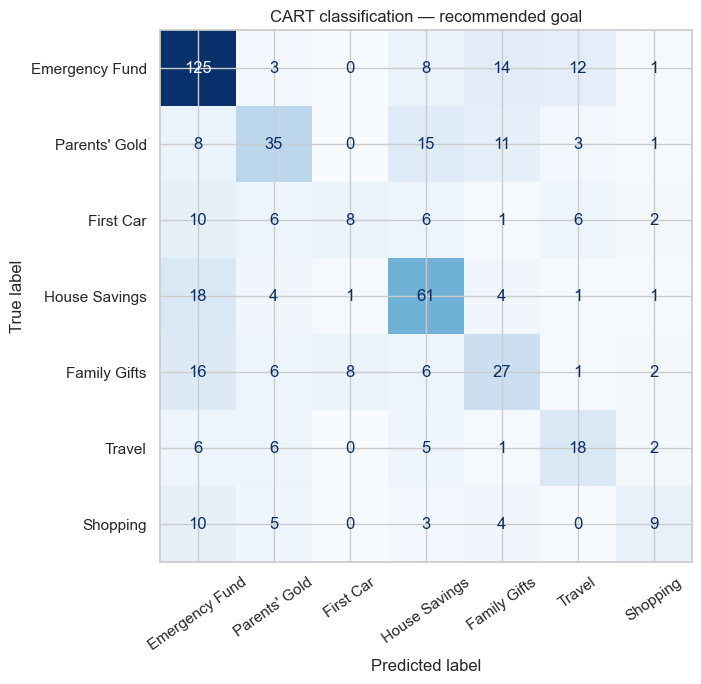

In [10]:

fig, ax = plt.subplots(figsize=(9, 7))
ConfusionMatrixDisplay.from_predictions(
    y_class_test, class_predictions,
    labels=goal_names, display_labels=goal_names,
    xticks_rotation=35, cmap="Blues", ax=ax, colorbar=False
)
ax.set_title("CART classification — recommended goal")
plt.tight_layout()
plt.show()


### 7.1 Visualise and interpret the classification tree

The diagram shows the upper levels for readability. The complete fitted tree and text rules are also available below.

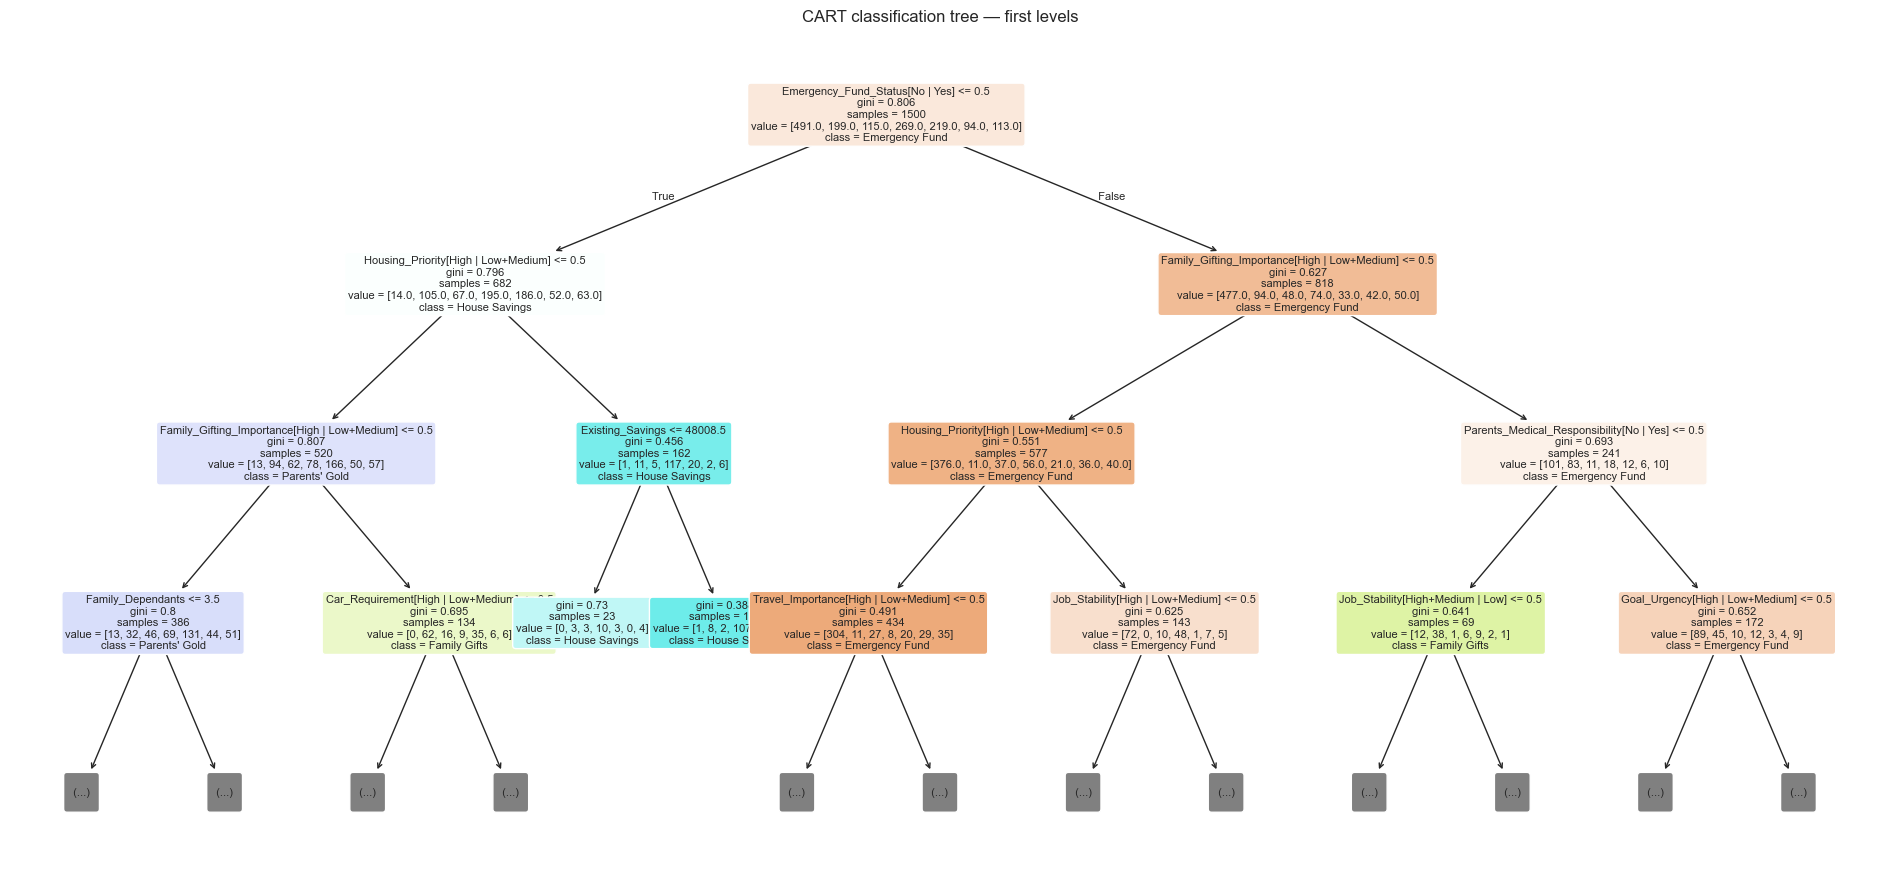

|--- Emergency_Fund_Status[No | Yes] <= 0.50
|   |--- Housing_Priority[High | Low+Medium] <= 0.50
|   |   |--- Family_Gifting_Importance[High | Low+Medium] <= 0.50
|   |   |   |--- Family_Dependants <= 3.50
|   |   |   |   |--- Shopping_Importance[High | Low+Medium] <= 0.50
|   |   |   |   |   |--- Travel_Importance[High | Low+Medium] <= 0.50
|   |   |   |   |   |   |--- truncated branch of depth 4
|   |   |   |   |   |--- Travel_Importance[High | Low+Medium] >  0.50
|   |   |   |   |   |   |--- class: Travel
|   |   |   |   |--- Shopping_Importance[High | Low+Medium] >  0.50
|   |   |   |   |   |--- Existing_Savings <= 129796.00
|   |   |   |   |   |   |--- class: Shopping
|   |   |   |   |   |--- Existing_Savings >  129796.00
|   |   |   |   |   |   |--- class: Parents' Gold
|   |   |   |--- Family_Dependants >  3.50
|   |   |   |   |--- class: Parents' Gold
|   |   |--- Family_Gifting_Importance[High | Low+Medium] >  0.50
|   |   |   |--- Car_Requirement[High | Low+Medium] <= 0.50
|

In [11]:

class_tree = best_classifier.named_steps["tree"]
encoded_names = best_classifier.named_steps["preprocess"].get_feature_names_out()

plt.figure(figsize=(24, 11))
plot_tree(
    class_tree,
    feature_names=encoded_names,
    class_names=[str(x) for x in class_tree.classes_],
    filled=True, rounded=True, max_depth=3, fontsize=8
)
plt.title("CART classification tree — first levels")
plt.show()

print(export_text(class_tree, feature_names=list(encoded_names), max_depth=5))


**Root-split check:** The manual table ranks candidate root splits by weighted Gini. "
"Here we inspect the root selected by the fitted CART model. The model may choose a different "
"feature because it optimizes its fitted preprocessing and stopping constraints.

In [12]:
# Compare the manually best root candidate with the fitted CART root.
class_root_index = class_tree.tree_.feature[0]
class_root_name = encoded_names[class_root_index] if class_root_index >= 0 else "Leaf"
print("Best manual root candidate:", best_gini_split["Feature"], "|", best_gini_split["Split"])
print("Fitted CART root feature:", class_root_name)
print("Fitted CART root threshold:", round(float(class_tree.tree_.threshold[0]), 5))
print("Root node Gini:", round(float(class_tree.tree_.impurity[0]), 5))
print("Root node samples:", int(class_tree.tree_.n_node_samples[0]))

Best manual root candidate: Emergency_Fund_Status | ['No'] | ['Yes']
Fitted CART root feature: Emergency_Fund_Status[No | Yes]
Fitted CART root threshold: 0.5
Root node Gini: 0.8063
Root node samples: 1500


## 8. CART regression — squared-error (MSE)

**Target:** `Recommended_Savings_Percentage`

Implementation: all binary categorical partitions + numeric features → `DecisionTreeRegressor(criterion="squared_error")` → cross-validation to tune tree depth, minimum leaf size and cost-complexity pruning → held-out evaluation.

In [13]:

baseline_regressor = DummyRegressor(strategy="mean")
baseline_regressor.fit(np.zeros((len(y_reg_train), 1)), y_reg_train)
baseline_reg_predictions = baseline_regressor.predict(np.zeros((len(y_reg_test), 1)))

print("Baseline MAE:", round(mean_absolute_error(y_reg_test, baseline_reg_predictions), 3))
print("Baseline RMSE:", round(np.sqrt(mean_squared_error(y_reg_test, baseline_reg_predictions)), 3))
print("Baseline R²:", round(r2_score(y_reg_test, baseline_reg_predictions), 3))

regression_pipeline = Pipeline([
    ("preprocess", preprocessor),
    ("tree", DecisionTreeRegressor(criterion="squared_error", random_state=RANDOM_STATE))
])

regression_grid = {
    "tree__max_depth": [3, 4, 5, 6, 8, 10, None],
    "tree__min_samples_leaf": [5, 10, 20, 30],
    "tree__ccp_alpha": [0.0, 0.01, 0.03, 0.06, 0.10]
}

regression_cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
regression_search = GridSearchCV(
    regression_pipeline,
    regression_grid,
    scoring="neg_root_mean_squared_error",
    cv=regression_cv,
    n_jobs=-1,
    refit=True
)
regression_search.fit(X_train, y_reg_train)

best_regressor = regression_search.best_estimator_
print("Best settings:", regression_search.best_params_)
print("Best cross-validation RMSE:", round(-regression_search.best_score_, 4))


Baseline MAE: 3.98
Baseline RMSE: 4.839
Baseline R²: -0.001
Best settings: {'tree__ccp_alpha': 0.06, 'tree__max_depth': 10, 'tree__min_samples_leaf': 5}
Best cross-validation RMSE: 3.1163


In [14]:

regression_predictions = best_regressor.predict(X_test)

regression_results = pd.Series({
    "MAE (percentage points)": mean_absolute_error(y_reg_test, regression_predictions),
    "RMSE (percentage points)": np.sqrt(mean_squared_error(y_reg_test, regression_predictions)),
    "R²": r2_score(y_reg_test, regression_predictions)
}, name="CART Regression")

display(regression_results.to_frame().round(4))


,CART Regression
MAE (percentage points),2.5726
RMSE (percentage points),3.1780
R²,0.5682


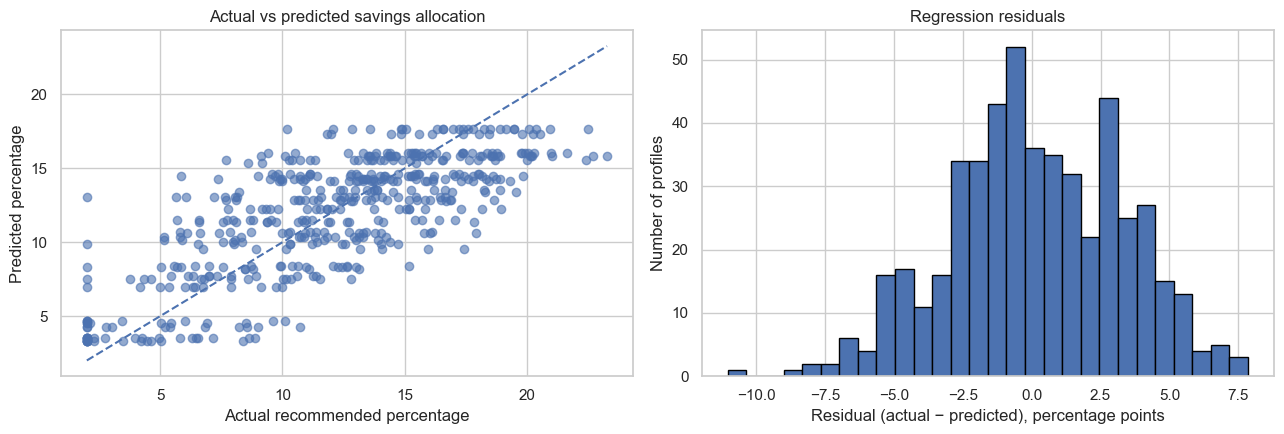

In [15]:

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].scatter(y_reg_test, regression_predictions, alpha=0.6)
low = min(y_reg_test.min(), regression_predictions.min())
high = max(y_reg_test.max(), regression_predictions.max())
axes[0].plot([low, high], [low, high], linestyle="--")
axes[0].set_xlabel("Actual recommended percentage")
axes[0].set_ylabel("Predicted percentage")
axes[0].set_title("Actual vs predicted savings allocation")

residuals = y_reg_test - regression_predictions
axes[1].hist(residuals, bins=28, edgecolor="black")
axes[1].set_xlabel("Residual (actual − predicted), percentage points")
axes[1].set_ylabel("Number of profiles")
axes[1].set_title("Regression residuals")
plt.tight_layout()
plt.show()


### 8.1 Visualise and interpret the regression tree

Each regression leaf predicts the mean target value of its training observations.

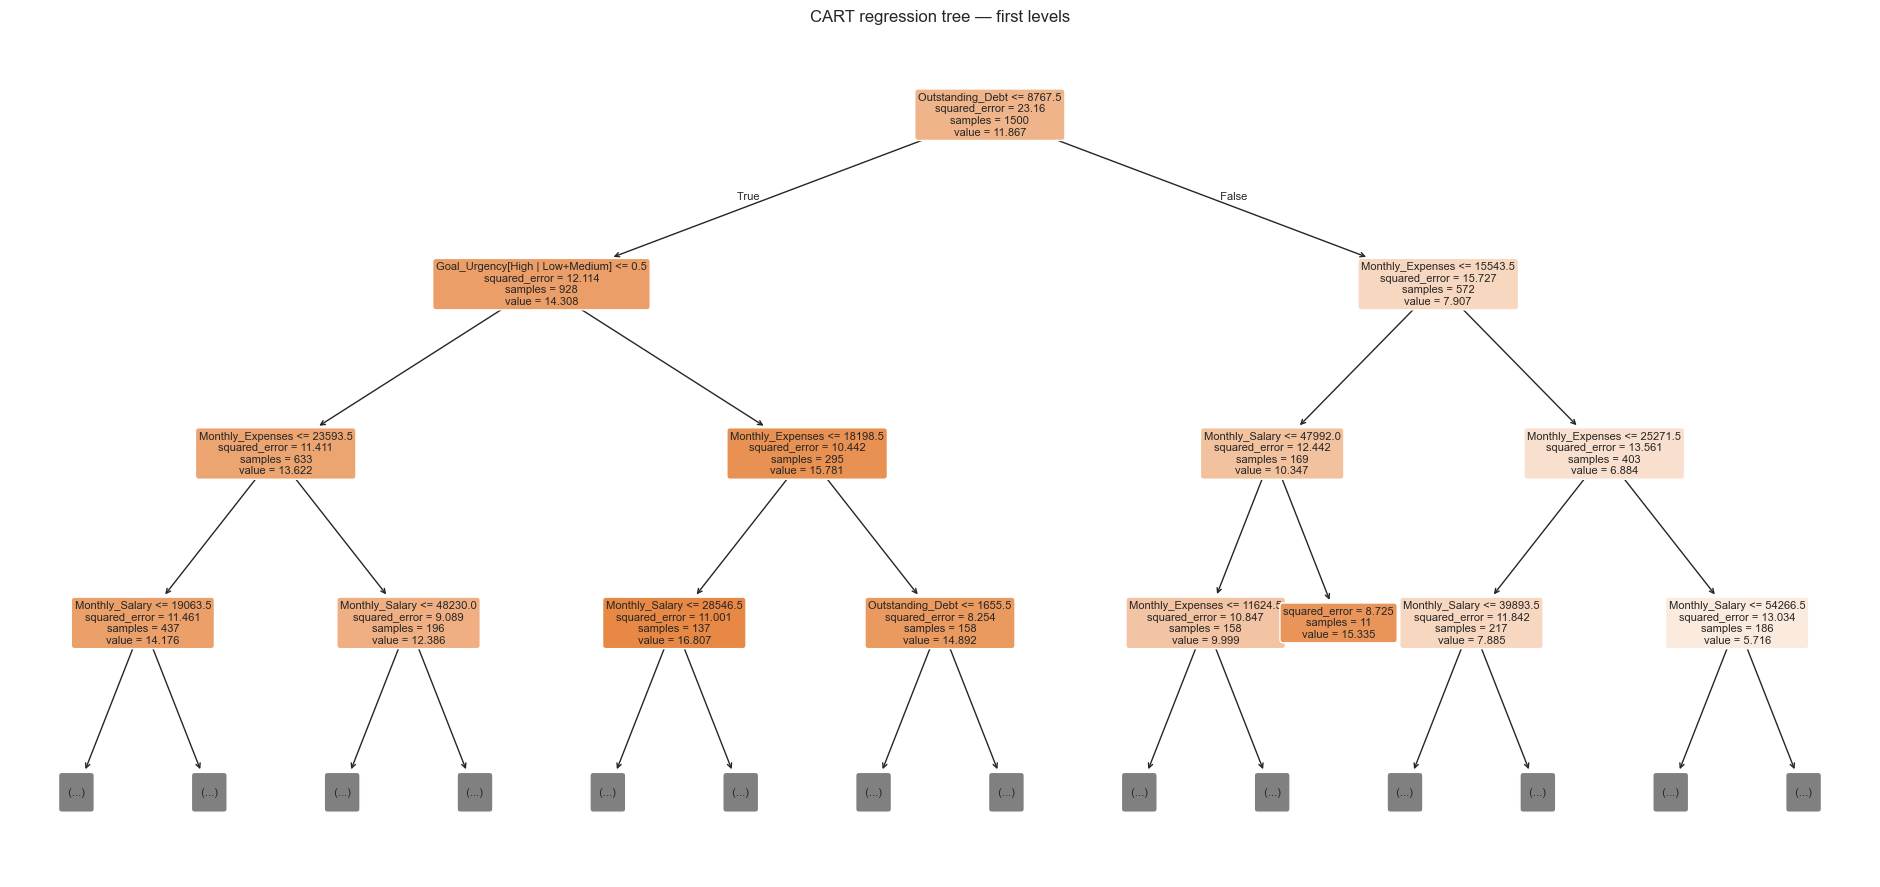

|--- Outstanding_Debt <= 8767.50
|   |--- Goal_Urgency[High | Low+Medium] <= 0.50
|   |   |--- Monthly_Expenses <= 23593.50
|   |   |   |--- Monthly_Salary <= 19063.50
|   |   |   |   |--- value: [9.57]
|   |   |   |--- Monthly_Salary >  19063.50
|   |   |   |   |--- Monthly_Salary <= 40181.00
|   |   |   |   |   |--- Monthly_Expenses <= 11528.50
|   |   |   |   |   |   |--- value: [15.57]
|   |   |   |   |   |--- Monthly_Expenses >  11528.50
|   |   |   |   |   |   |--- truncated branch of depth 3
|   |   |   |   |--- Monthly_Salary >  40181.00
|   |   |   |   |   |--- Risk_Tolerance[High+Medium | Low] <= 0.50
|   |   |   |   |   |   |--- value: [14.27]
|   |   |   |   |   |--- Risk_Tolerance[High+Medium | Low] >  0.50
|   |   |   |   |   |   |--- value: [16.01]
|   |   |--- Monthly_Expenses >  23593.50
|   |   |   |--- Monthly_Salary <= 48230.00
|   |   |   |   |--- value: [10.60]
|   |   |   |--- Monthly_Salary >  48230.00
|   |   |   |   |--- Monthly_Expenses <= 29324.50
|   |   | 

In [16]:

regression_tree = best_regressor.named_steps["tree"]
regression_feature_names = best_regressor.named_steps["preprocess"].get_feature_names_out()

plt.figure(figsize=(24, 11))
plot_tree(
    regression_tree,
    feature_names=regression_feature_names,
    filled=True, rounded=True, max_depth=3, fontsize=8
)
plt.title("CART regression tree — first levels")
plt.show()

print(export_text(
    regression_tree,
    feature_names=list(regression_feature_names),
    max_depth=5
))


**Root-split check:** The manual MSE table ranks candidate root splits. "
"Inspect the fitted regression tree's root feature and threshold to connect the manual "
"split calculation with the learned model.

In [17]:
# Compare the manually best root candidate with the fitted CART regression root.
reg_root_index = regression_tree.tree_.feature[0]
reg_root_name = regression_feature_names[reg_root_index] if reg_root_index >= 0 else "Leaf"
print("Best manual root candidate:", best_mse_split["Feature"], "|", best_mse_split["Split"])
print("Fitted CART root feature:", reg_root_name)
print("Fitted CART root threshold:", round(float(regression_tree.tree_.threshold[0]), 5))
print("Root node MSE:", round(float(regression_tree.tree_.impurity[0]), 5))
print("Root node samples:", int(regression_tree.tree_.n_node_samples[0]))

Best manual root candidate: Outstanding_Debt | Outstanding_Debt <= 8767.5
Fitted CART root feature: Outstanding_Debt
Fitted CART root threshold: 8767.5
Root node MSE: 23.15951
Root node samples: 1500


## 9. Model comparison and pruning

Compare a majority/mean baseline, an unrestricted tree, a pre-pruned tree and the tuned cost-complexity-pruned tree. Training, cross-validation and held-out test scores show the effect of controlling tree complexity.

,Depth,Leaves,CV balanced accuracy,Train balanced accuracy,Test balanced accuracy,Test macro F1
Model,,,,,,
Majority baseline,NaN,NaN,0.1429,0.1429,0.1429,0.0702
Full tree,18.0,521.0,0.3673,1.0000,0.3599,0.3560
Pre-pruned tree,12.0,112.0,0.4555,0.5827,0.4509,0.4594
Post-pruned tree,9.0,34.0,0.4687,0.5363,0.4718,0.4813


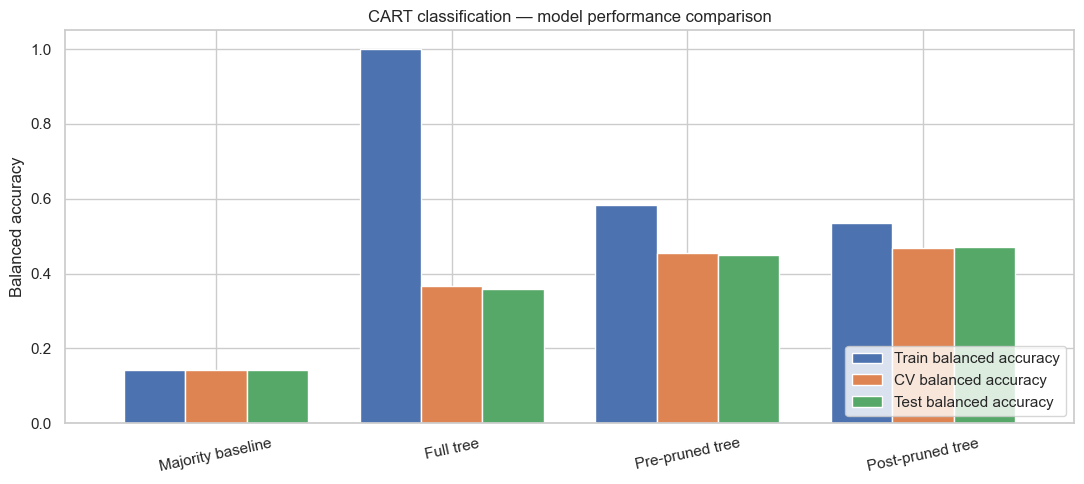

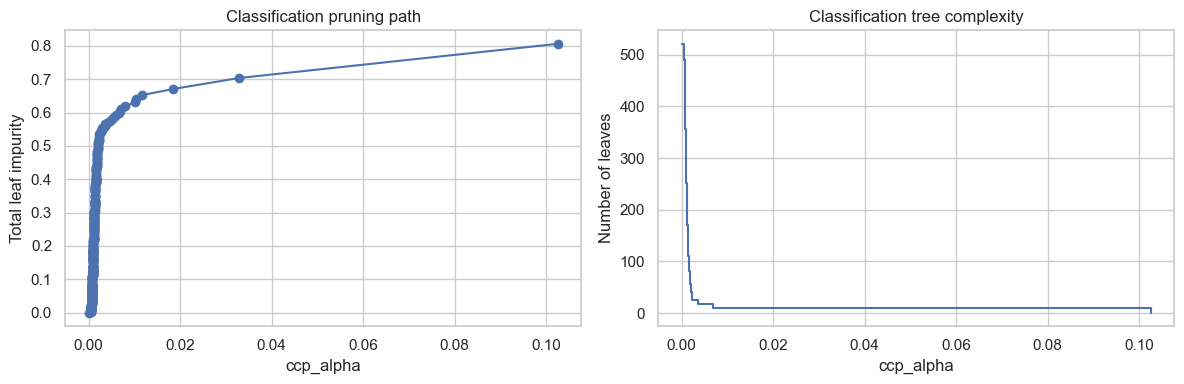

,Depth,Leaves,CV RMSE,Train RMSE,Test RMSE,Test MAE,Test R²
Model,,,,,,,
Mean baseline,NaN,NaN,4.8151,4.8124,4.8390,3.9802,-0.0012
Full tree,21.0,1444.0,3.9149,0.0000,4.0440,3.1986,0.3008
Pre-pruned tree,10.0,200.0,3.3393,1.9309,3.4483,2.7570,0.4916
Post-pruned tree,8.0,38.0,3.1163,2.6323,3.1780,2.5726,0.5682


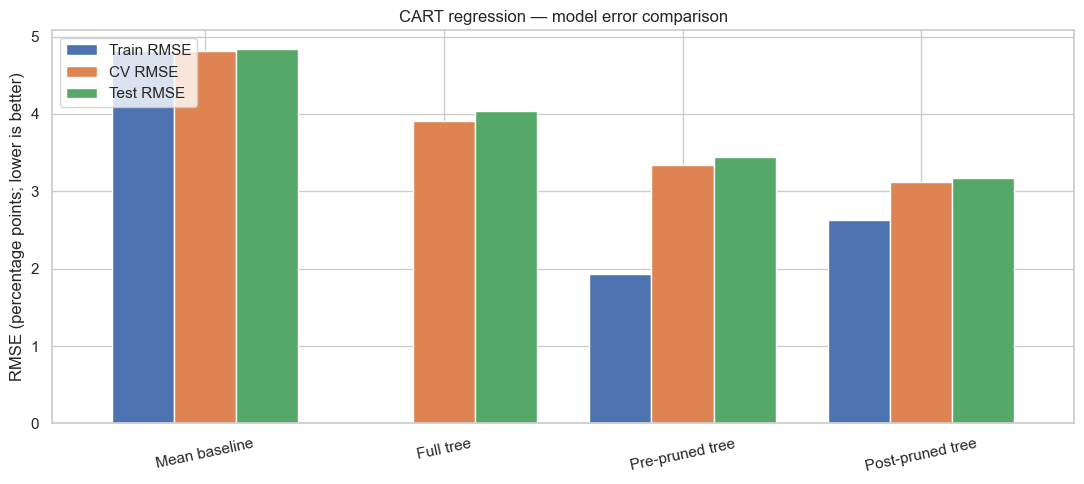

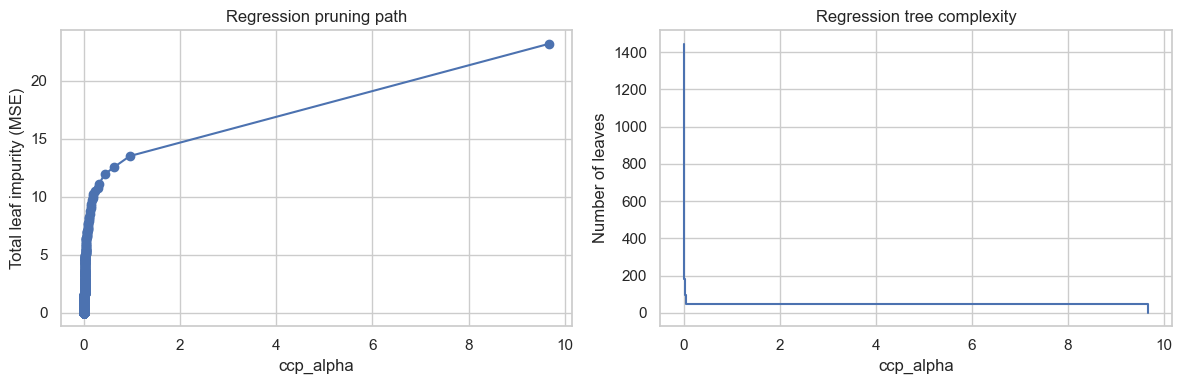

Interpretation: a useful pruned tree should reduce unnecessary complexity
while maintaining validation and test performance. Compare the metrics above;
do not select a model from training performance alone.


In [18]:
from sklearn.base import clone
from sklearn.model_selection import cross_val_score
from sklearn.metrics import balanced_accuracy_score

# Classification: compare baseline, unrestricted, pre-pruned and tuned/pruned CART.
class_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
class_full = clone(best_classifier).set_params(
    tree__max_depth=None, tree__min_samples_leaf=1, tree__ccp_alpha=0.0
)
class_prepruned = clone(best_classifier).set_params(tree__ccp_alpha=0.0)
class_postpruned = clone(best_classifier)

class_models = {
    "Majority baseline": DummyClassifier(strategy="most_frequent"),
    "Full tree": class_full,
    "Pre-pruned tree": class_prepruned,
    "Post-pruned tree": class_postpruned
}
class_rows = []
for name, model in class_models.items():
    model.fit(X_train, y_class_train)
    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)
    cv_scores = cross_val_score(
        model, X_train, y_class_train, cv=class_cv,
        scoring="balanced_accuracy", n_jobs=-1
    )
    fitted_tree = model.named_steps["tree"] if isinstance(model, Pipeline) else None
    class_rows.append({
        "Model": name,
        "Depth": fitted_tree.get_depth() if fitted_tree is not None else np.nan,
        "Leaves": fitted_tree.get_n_leaves() if fitted_tree is not None else np.nan,
        "CV balanced accuracy": cv_scores.mean(),
        "Train balanced accuracy": balanced_accuracy_score(y_class_train, train_pred),
        "Test balanced accuracy": balanced_accuracy_score(y_class_test, test_pred),
        "Test macro F1": f1_score(y_class_test, test_pred, average="macro")
    })

classification_comparison = pd.DataFrame(class_rows).set_index("Model")
display(classification_comparison.round(4))

ax = classification_comparison[[
    "Train balanced accuracy", "CV balanced accuracy", "Test balanced accuracy"
]].plot(kind="bar", figsize=(11, 5), ylim=(0, 1.05), width=0.78)
ax.set_title("CART classification — model performance comparison")
ax.set_ylabel("Balanced accuracy")
ax.set_xlabel("")
ax.tick_params(axis="x", rotation=12)
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

# Cost-complexity pruning path: larger alpha generally produces a smaller tree.
class_X_train_encoded = best_classifier.named_steps["preprocess"].transform(X_train)
class_pruning_path = DecisionTreeClassifier(
    criterion="gini", random_state=RANDOM_STATE
).cost_complexity_pruning_path(class_X_train_encoded, y_class_train)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(class_pruning_path.ccp_alphas, class_pruning_path.impurities, marker="o")
axes[0].set_title("Classification pruning path")
axes[0].set_xlabel("ccp_alpha")
axes[0].set_ylabel("Total leaf impurity")
class_alpha_idx = np.unique(np.linspace(
    0, len(class_pruning_path.ccp_alphas)-1,
    min(40, len(class_pruning_path.ccp_alphas)), dtype=int
))
class_alpha_sample = class_pruning_path.ccp_alphas[class_alpha_idx]
class_leaf_counts = [
    DecisionTreeClassifier(random_state=RANDOM_STATE, ccp_alpha=a)
    .fit(class_X_train_encoded, y_class_train).get_n_leaves()
    for a in class_alpha_sample
]
axes[1].step(class_alpha_sample, class_leaf_counts, where="post")
axes[1].set_title("Classification tree complexity")
axes[1].set_xlabel("ccp_alpha")
axes[1].set_ylabel("Number of leaves")
plt.tight_layout()
plt.show()

# Regression: compare mean baseline, unrestricted, pre-pruned and tuned/pruned CART.
reg_cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
reg_full = clone(best_regressor).set_params(
    tree__max_depth=None, tree__min_samples_leaf=1, tree__ccp_alpha=0.0
)
reg_prepruned = clone(best_regressor).set_params(tree__ccp_alpha=0.0)
reg_postpruned = clone(best_regressor)

reg_models = {
    "Mean baseline": DummyRegressor(strategy="mean"),
    "Full tree": reg_full,
    "Pre-pruned tree": reg_prepruned,
    "Post-pruned tree": reg_postpruned
}
reg_rows = []
for name, model in reg_models.items():
    model.fit(X_train, y_reg_train)
    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)
    cv_rmse = -cross_val_score(
        model, X_train, y_reg_train, cv=reg_cv,
        scoring="neg_root_mean_squared_error", n_jobs=-1
    )
    fitted_tree = model.named_steps["tree"] if isinstance(model, Pipeline) else None
    reg_rows.append({
        "Model": name,
        "Depth": fitted_tree.get_depth() if fitted_tree is not None else np.nan,
        "Leaves": fitted_tree.get_n_leaves() if fitted_tree is not None else np.nan,
        "CV RMSE": cv_rmse.mean(),
        "Train RMSE": np.sqrt(mean_squared_error(y_reg_train, train_pred)),
        "Test RMSE": np.sqrt(mean_squared_error(y_reg_test, test_pred)),
        "Test MAE": mean_absolute_error(y_reg_test, test_pred),
        "Test R²": r2_score(y_reg_test, test_pred)
    })

regression_comparison = pd.DataFrame(reg_rows).set_index("Model")
display(regression_comparison.round(4))

ax = regression_comparison[["Train RMSE", "CV RMSE", "Test RMSE"]].plot(
    kind="bar", figsize=(11, 5), width=0.78
)
ax.set_title("CART regression — model error comparison")
ax.set_ylabel("RMSE (percentage points; lower is better)")
ax.set_xlabel("")
ax.tick_params(axis="x", rotation=12)
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

reg_X_train_encoded = best_regressor.named_steps["preprocess"].transform(X_train)
reg_pruning_path = DecisionTreeRegressor(
    criterion="squared_error", random_state=RANDOM_STATE
).cost_complexity_pruning_path(reg_X_train_encoded, y_reg_train)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(reg_pruning_path.ccp_alphas, reg_pruning_path.impurities, marker="o")
axes[0].set_title("Regression pruning path")
axes[0].set_xlabel("ccp_alpha")
axes[0].set_ylabel("Total leaf impurity (MSE)")
reg_alpha_idx = np.unique(np.linspace(
    0, len(reg_pruning_path.ccp_alphas)-1,
    min(40, len(reg_pruning_path.ccp_alphas)), dtype=int
))
reg_alpha_sample = reg_pruning_path.ccp_alphas[reg_alpha_idx]
reg_leaf_counts = [
    DecisionTreeRegressor(random_state=RANDOM_STATE, ccp_alpha=a)
    .fit(reg_X_train_encoded, y_reg_train).get_n_leaves()
    for a in reg_alpha_sample
]
axes[1].step(reg_alpha_sample, reg_leaf_counts, where="post")
axes[1].set_title("Regression tree complexity")
axes[1].set_xlabel("ccp_alpha")
axes[1].set_ylabel("Number of leaves")
plt.tight_layout()
plt.show()

print("Interpretation: a useful pruned tree should reduce unnecessary complexity")
print("while maintaining validation and test performance. Compare the metrics above;")
print("do not select a model from training performance alone.")

### Why is the accuracy not higher?

The classification accuracy (about 0.57) and regression R² (about 0.57) are moderate, and this is expected for this dataset, not a weakness of the CART implementation.

- **The targets contain random noise.** Each synthetic target is built from a scoring formula plus random variation (panel noise and individual preference for the goal; allocation noise and preference for the savings percentage). That variation is not stored in any input column, so no model can predict it.
- **There is a ceiling.** Even a model that knew the exact noise-free formula would match the final goal labels only about 65% of the time and explain about 75% of the variance in savings percentage. The tuned trees reach about 87% and 76% of those ceilings.
- **The trees clearly learn real structure.** Accuracy is 0.566 against a majority-class baseline of 0.326, and R² is 0.568 against a mean baseline of about 0.
- **The pruned trees generalise better.** The unrestricted tree scores 1.00 on training data but only 0.36 balanced accuracy on test data, while the pruned tree is stable.
- **Rare goals are harder.** First Car and Shopping make up only 6–8% of the profiles, so a leaf rarely has a majority of them and they are often predicted as another goal.

The aim here is to show the CART method (impurity-based splitting, pruning, evaluation), not to build a validated financial advisor.

## 10. Feature importance

Compare which encoded input features the fitted classification and regression trees used most. Importance is specific to these synthetic data and fitted models.

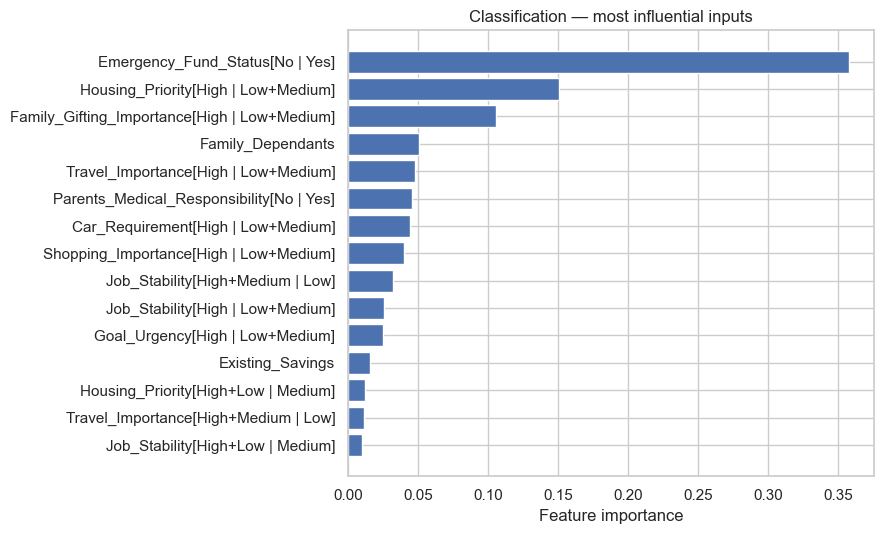

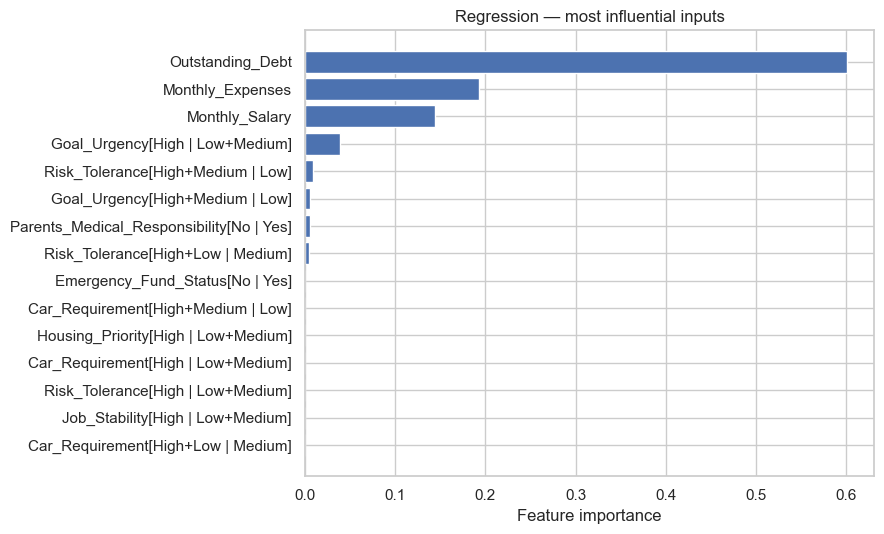

In [19]:

def show_feature_importance(model, title, top_n=15):
    tree_model = model.named_steps["tree"]
    names = model.named_steps["preprocess"].get_feature_names_out()
    importance = pd.Series(tree_model.feature_importances_, index=names)
    top = importance.sort_values(ascending=False).head(top_n).sort_values()
    plt.figure(figsize=(9, 5.5))
    plt.barh(top.index, top.values)
    plt.xlabel("Feature importance")
    plt.title(title)
    plt.tight_layout()
    plt.show()
    return importance.sort_values(ascending=False)

class_importance = show_feature_importance(
    best_classifier, "Classification — most influential inputs"
)
reg_importance = show_feature_importance(
    best_regressor, "Regression — most influential inputs"
)


## 11. Check predictions on unseen test profiles

Compare the actual simulated target with the prediction for profiles that were not used to fit the final tree.

In [20]:

example_rows = X_test.head(12).copy()
example_rows["Actual_Recommended_Goal"] = y_class_test.loc[example_rows.index]
example_rows["Predicted_Recommended_Goal"] = best_classifier.predict(example_rows)
example_rows["Actual_Savings_Percentage"] = y_reg_test.loc[example_rows.index]
example_rows["Predicted_Savings_Percentage"] = best_regressor.predict(example_rows).round(2)

display(example_rows[[
    "Monthly_Salary", "Monthly_Expenses", "Existing_Savings",
    "Emergency_Fund_Status", "Family_Dependants", "Job_Stability",
    "Actual_Recommended_Goal", "Predicted_Recommended_Goal",
    "Actual_Savings_Percentage", "Predicted_Savings_Percentage"
]])


,Monthly_Salary,Monthly_Expenses,Existing_Savings,Emergency_Fund_Status,Family_Dependants,Job_Stability,Actual_Recommended_Goal,Predicted_Recommended_Goal,Actual_Savings_Percentage,Predicted_Savings_Percentage
1324,45815.0,26995.0,42921.0,No,1,High,Emergency Fund,Emergency Fund,3.95,3.49
348,23027.0,15203.0,63105.0,Yes,4,Low,Parents' Gold,Parents' Gold,13.91,10.17
1210,58829.0,28529.0,61401.0,No,1,Medium,Family Gifts,Family Gifts,12.99,14.59
183,63947.0,23003.0,442965.0,Yes,4,Low,Travel,Parents' Gold,9.35,11.34
1767,57840.0,30860.0,219129.0,Yes,4,High,Parents' Gold,Parents' Gold,13.13,8.19
1417,61311.0,36378.0,109528.0,Yes,0,High,Shopping,Parents' Gold,10.11,4.64
1054,24886.0,10598.0,43330.0,Yes,2,Medium,First Car,First Car,14.88,15.57
265,61713.0,35468.0,26051.0,No,3,High,First Car,House Savings,15.25,13.54
1475,39480.0,21844.0,14534.0,No,1,High,House Savings,House Savings,11.84,12.23
1871,33926.0,12106.0,485642.0,Yes,3,High,Parents' Gold,Family Gifts,20.09,17.65


## 12. Predict for a new financial profile

Change the input values to test another hypothetical profile. The prediction is an output of the trained CART models, not personal financial advice.

In [21]:

new_person = pd.DataFrame([{
    "Monthly_Salary": 55000,
    "Monthly_Expenses": 25000,
    "Existing_Savings": 30000,
    "Emergency_Fund_Status": "No",
    "Family_Dependants": 2,
    "Outstanding_Debt": 0,
    "Job_Stability": "Medium",
    "Parents_Medical_Responsibility": "No",
    "Car_Requirement": "Medium",
    "Housing_Priority": "High",
    "Risk_Tolerance": "Low",
    "Goal_Urgency": "High",
    "Family_Gifting_Importance": "High",
    "Travel_Importance": "Medium",
    "Shopping_Importance": "Medium",
    "Transport_Access": "Limited",
    "Financial_Support_Network": "Available"
}])

predicted_goal = best_classifier.predict(new_person)[0]
predicted_percentage = best_regressor.predict(new_person)[0]

print("Recommended first priority (CART classification):", predicted_goal)
print("Recommended monthly allocation (CART regression):", round(predicted_percentage, 2), "% of salary")
print("Approximate monthly amount: ₹", round(55000 * predicted_percentage / 100, 0))


Recommended first priority (CART classification): Emergency Fund
Recommended monthly allocation (CART regression): 14.13 % of salary
Approximate monthly amount: ₹ 7773.0


## 13. Implementation summary

This notebook demonstrates two CART implementations on the same input domain:

- Classification tree: Gini impurity and majority-class leaf prediction.
- Regression tree: squared-error reduction and mean-value leaf prediction.
- Training/test separation and training-only cross-validation.
- Pre-pruning controls (`max_depth`, `min_samples_leaf`) and cost-complexity pruning (`ccp_alpha`).
- Held-out metrics, tree visualisation, feature importance and new-profile prediction.

The dataset and labels are synthetic; results demonstrate implementation, not validated financial recommendations.